# Human Activity Recognition from Video (UCF101, Kaggle)

Pipeline: **YOLOv8 person detection → DeepSORT tracking → ResNet50 features → LSTM**.

In [1]:
!pip -q install deep-sort-realtime ultralytics

In [3]:
import os, glob, re
import pandas as pd
from collections import Counter

ROOT = "/kaggle/input/datasets/matthewjansen/ucf101-action-recognition"
print(os.listdir(ROOT))

# the CSVs
for s in ("train", "val", "test"):
    df = pd.read_csv(f"{ROOT}/{s}.csv")
    print(f"\n{s}.csv: {len(df)} rows, columns = {list(df.columns)}")
    print(df.head(2).to_string())

# the videos, per split folder
paths = [p for ext in ("avi", "mp4") for p in glob.glob(f"{ROOT}/**/*.{ext}", recursive=True)]
print("\nvideo files found:", len(paths))
print("example files:", [os.path.basename(p) for p in paths[:3]])

split_counts = Counter(p.split(ROOT + "/")[1].split("/")[0] for p in paths)
print("videos per split folder:", dict(split_counts))

# do the file names contain the group number (g01...g25)?
pat = re.compile(r"v_(.+)_g(\d+)_c(\d+)", re.I)
ok = sum(1 for p in paths if pat.search(os.path.basename(p)))
print(f"file names matching v_<Class>_g<group>_c<clip>: {ok}/{len(paths)}")

classes = sorted({os.path.basename(os.path.dirname(p)) for p in paths})
print(f"\n{len(classes)} classes:\n{classes}")

['test', 'test.csv', 'train', 'train.csv', 'val', 'val.csv']

train.csv: 10055 rows, columns = ['clip_name', 'clip_path', 'label']
         clip_name                         clip_path  label
0  v_Swing_g05_c02  /train/Swing/v_Swing_g05_c02.avi  Swing
1  v_Swing_g21_c03  /train/Swing/v_Swing_g21_c03.avi  Swing

val.csv: 1673 rows, columns = ['clip_name', 'clip_path', 'label']
         clip_name                       clip_path  label
0  v_Swing_g22_c05  /val/Swing/v_Swing_g22_c05.avi  Swing
1  v_Swing_g25_c02  /val/Swing/v_Swing_g25_c02.avi  Swing

test.csv: 1723 rows, columns = ['clip_name', 'clip_path', 'label']
         clip_name                        clip_path  label
0  v_Swing_g21_c02  /test/Swing/v_Swing_g21_c02.avi  Swing
1  v_Swing_g21_c06  /test/Swing/v_Swing_g21_c06.avi  Swing

video files found: 13451
example files: ['v_ApplyEyeMakeup_g01_c02.avi', 'v_ApplyEyeMakeup_g01_c04.avi', 'v_ApplyEyeMakeup_g02_c01.avi']
videos per split folder: {'test': 1723, 'train': 10055, 'val': 16

In [4]:
import os, re, glob, time, random
import numpy as np
import cv2
import torch
import torch.nn as nn

CLASSES = ["WalkingWithDog", "JumpingJack", "LongJump", "CliffDiving", "BenchPress"]
STRIDE   = 2     
WINDOW   = 16   
WIN_STEP = 4
EPOCHS   = 40
SEED     = 0
WORK     = "/kaggle/working"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "(no GPU: turn on the accelerator, this will be very slow)")
os.chdir(WORK)

device: cuda Tesla T4


## 1. Find the videos and build the group-based split

In [5]:
ROOT = "/kaggle/input/datasets/matthewjansen/ucf101-action-recognition"

paths = [p for ext in ("avi", "mp4") for p in glob.glob(f"{ROOT}/**/*.{ext}", recursive=True)]
assert paths, "No videos found. Check that the dataset is added under 'Input'."

pat = re.compile(r"v_(.+)_g(\d+)_c(\d+)", re.I)
use_groups = all(pat.search(os.path.basename(p)) for p in paths)
print("video files:", len(paths), "| group number found in file names:", use_groups)
print("example files:", [os.path.basename(p) for p in paths[:3]])

all_classes = sorted({os.path.basename(os.path.dirname(p)) for p in paths})
by_lower = {c.lower(): c for c in all_classes}
missing = [c for c in CLASSES if c.lower() not in by_lower]
assert not missing, f"Not found: {missing}"
CLASSES = [by_lower[c.lower()] for c in CLASSES]

items = {"train": [], "val": [], "test": []}          # (class_index, video_path)
for p in paths:
    c = os.path.basename(os.path.dirname(p))
    if c not in CLASSES:
        continue
    if use_groups:      # group-based split: test g1-7, val g8-11, train g12-25
        g = int(pat.search(os.path.basename(p)).group(2))
        split = "test" if g <= 7 else "val" if g <= 11 else "train"
    else:               # otherwise use the dataset's own train/val/test folders
        split = p.split(ROOT + "/")[1].split("/")[0]
        if split not in items:
            continue
    items[split].append((CLASSES.index(c), p))

print("split used:", "UCF101 groups (official split 1)" if use_groups else "dataset's own train/val/test folders")
for c in CLASSES:
    print(f"{c:20s}", {s: sum(1 for ci, _ in items[s] if CLASSES[ci] == c) for s in items})
print("videos per split:", {k: len(v) for k, v in items.items()})

video files: 13451 | group number found in file names: True
example files: ['v_ApplyEyeMakeup_g01_c02.avi', 'v_ApplyEyeMakeup_g01_c04.avi', 'v_ApplyEyeMakeup_g02_c01.avi']
split used: UCF101 groups (official split 1)
WalkingWithDog       {'train': 66, 'val': 21, 'test': 36}
JumpingJack          {'train': 65, 'val': 21, 'test': 37}
LongJump             {'train': 67, 'val': 25, 'test': 39}
CliffDiving          {'train': 76, 'val': 23, 'test': 39}
BenchPress           {'train': 89, 'val': 23, 'test': 48}
videos per split: {'train': 363, 'val': 113, 'test': 199}


## 2. Models: detection + tracking + feature extractor

In [7]:
from torchvision import models, transforms
from ultralytics import YOLO
from deep_sort_realtime.deepsort_tracker import DeepSort

class PersonFeatureExtractor:
    def __init__(self, det_weights="yolov8n.pt", conf=0.4):
        self.conf = conf
        self.det = YOLO(det_weights)
        cnn = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        cnn.fc = nn.Identity()
        self.cnn = cnn.eval().to(DEV)
        self.prep = transforms.Compose([
            transforms.ToPILImage(), transforms.Resize((224, 224)), transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
        self.reset()

    def reset(self):
        self.tracker = DeepSort(max_age=15)

    @torch.no_grad()
    def step(self, frame):
        """frame: BGR image -> list of (track_id, (l, t, r, b), feature[2048])"""
        res = self.det.predict(frame, classes=[0], conf=self.conf, verbose=False)[0]
        dets = []
        for b in res.boxes:
            x1, y1, x2, y2 = b.xyxy[0].tolist()
            dets.append(([x1, y1, x2 - x1, y2 - y1], float(b.conf[0]), "person"))
        tracks = self.tracker.update_tracks(dets, frame=frame)
        h, w = frame.shape[:2]
        out = []
        for t in tracks:
            if not t.is_confirmed() or t.time_since_update > 0:
                continue
            l, tp, r, bt = [int(v) for v in t.to_ltrb()]
            l, tp, r, bt = max(l, 0), max(tp, 0), min(r, w), min(bt, h)
            if r - l < 8 or bt - tp < 8:
                continue
            crop = cv2.cvtColor(frame[tp:bt, l:r], cv2.COLOR_BGR2RGB)
            x = self.prep(crop).unsqueeze(0).to(DEV)
            out.append((t.track_id, (l, tp, r, bt), self.cnn(x).squeeze(0).cpu().numpy().astype(np.float32)))
        return out

class LSTMClassifier(nn.Module):
    def __init__(self, n_classes, in_dim=2048, hidden=256):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden, n_classes)
    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.fc(self.drop(h[-1]))

ext = PersonFeatureExtractor()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 200MB/s]
/usr/local/lib/python3.13/dist-packages/deep_sort_realtime/embedder/embedder_pytorch.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## 3. Extract one feature sequence per video (longest track = main person)

In [8]:
from collections import defaultdict
from tqdm.auto import tqdm

os.makedirs("features", exist_ok=True)

def video_features(path):
    ext.reset()
    cap = cv2.VideoCapture(path)
    seqs, i = defaultdict(list), 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i % STRIDE == 0:
            for tid, _, feat in ext.step(frame):
                seqs[tid].append(feat)
        i += 1
    cap.release()
    return np.stack(max(seqs.values(), key=len)) if seqs else None

feats, skipped = {}, []
all_items = items["train"] + items["val"] + items["test"]
for ci, path in tqdm(all_items):
    cache = f"features/{os.path.basename(path)}.npy"
    if os.path.exists(cache):
        feats[(ci, path)] = np.load(cache); continue
    seq = video_features(path)
    if seq is None or len(seq) < 4:
        skipped.append((ci, path)); continue
    np.save(cache, seq); feats[(ci, path)] = seq
print("videos with features:", len(feats), "| skipped (no person detected):", len(skipped))

  0%|          | 0/675 [00:00<?, ?it/s]

videos with features: 547 | skipped (no person detected): 128


## 4. Build windows and train the LSTM

In [9]:
def windows(seq):
    if len(seq) < WINDOW:                                   # pad short tracks by repeating the last frame
        seq = np.concatenate([seq, np.repeat(seq[-1:], WINDOW - len(seq), 0)])
    return np.stack([seq[i:i + WINDOW] for i in range(0, len(seq) - WINDOW + 1, WIN_STEP)])

def build(its):
    X, y, v = [], [], []
    for k, it in enumerate(its):
        w = windows(feats[it])
        X.append(w); y += [it[0]] * len(w); v += [k] * len(w)
    return np.concatenate(X).astype(np.float32), np.array(y), np.array(v)

tr = [it for it in items["train"] if it in feats]
va = [it for it in items["val"] if it in feats]
te_all = [it for it in items["test"] if it in feats]
print(f"videos train/val/test = {len(tr)}/{len(va)}/{len(te_all)}")

Xtr, ytr, _ = build(tr); Xva, yva, _ = build(va); Xte, yte, vte = build(te_all)
print(f"windows train/val/test = {len(Xtr)}/{len(Xva)}/{len(Xte)}")

counts = np.bincount(ytr, minlength=len(CLASSES))
weights = torch.tensor(len(ytr) / (len(CLASSES) * np.maximum(counts, 1)), dtype=torch.float32).to(DEV)

@torch.no_grad()
def predict(model, X):
    model.eval()
    return torch.cat([model(torch.from_numpy(X[i:i + 256]).to(DEV)).cpu() for i in range(0, len(X), 256)])

model = LSTMClassifier(len(CLASSES)).to(DEV)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
lossf = nn.CrossEntropyLoss(weight=weights)
Xtr_t, ytr_t = torch.from_numpy(Xtr), torch.from_numpy(ytr)
best, best_state = -1, None
for ep in range(EPOCHS):
    model.train()
    perm = torch.randperm(len(Xtr_t))
    for i in range(0, len(perm), 64):
        idx = perm[i:i + 64]
        opt.zero_grad()
        loss = lossf(model(Xtr_t[idx].to(DEV)), ytr_t[idx].to(DEV))
        loss.backward(); opt.step()
    va_acc = (predict(model, Xva).argmax(1).numpy() == yva).mean()
    if va_acc > best:
        best, best_state = va_acc, {k: v.clone() for k, v in model.state_dict().items()}
    if (ep + 1) % 5 == 0:
        print(f"epoch {ep + 1:02d}  loss {loss.item():.3f}  val acc {va_acc:.3f}")
model.load_state_dict(best_state)
torch.save({"state": model.state_dict(), "classes": CLASSES, "window": WINDOW}, "har_lstm.pt")
print("best val acc:", round(float(best), 4))

videos train/val/test = 295/89/163
windows train/val/test = 2174/597/1331
epoch 05  loss 0.004  val acc 0.891
epoch 10  loss 0.001  val acc 0.896
epoch 15  loss 0.000  val acc 0.901
epoch 20  loss 0.000  val acc 0.901
epoch 25  loss 0.000  val acc 0.901
epoch 30  loss 0.000  val acc 0.903
epoch 35  loss 0.000  val acc 0.905
epoch 40  loss 0.000  val acc 0.903
best val acc: 0.9045


## 5. Evaluate on the held-out test videos

                precision    recall  f1-score   support

WalkingWithDog      0.892     0.961     0.925       532
   JumpingJack      0.917     0.843     0.879       223
      LongJump      0.929     0.832     0.878       250
   CliffDiving      0.759     0.733     0.746        30
    BenchPress      0.923     0.936     0.930       296

      accuracy                          0.906      1331
     macro avg      0.884     0.861     0.871      1331
  weighted avg      0.907     0.906     0.905      1331



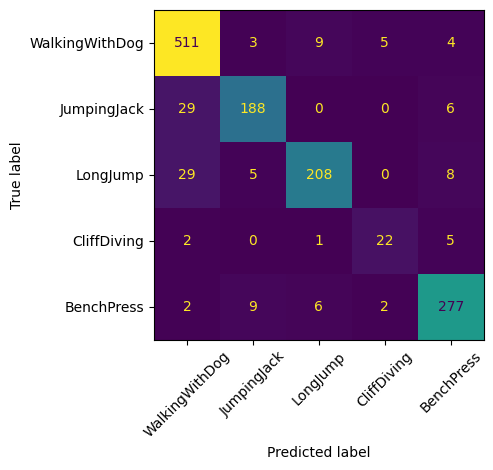

TEST windows: acc 0.9061, macro-F1 0.8713 | TEST videos: acc 0.8589, macro-F1 0.8626 (163 videos)


In [10]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

logits = predict(model, Xte)
pred = logits.argmax(1).numpy()
win_acc = float((pred == yte).mean())
macro_f1 = float(f1_score(yte, pred, average="macro"))

vt, vp = [], []
for k in np.unique(vte):
    m = vte == k
    vt.append(yte[m][0]); vp.append(logits[torch.from_numpy(m)].mean(0).argmax().item())
vid_acc = float((np.array(vt) == np.array(vp)).mean())
vid_f1 = float(f1_score(vt, vp, average="macro"))

print(classification_report(yte, pred, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=CLASSES).plot(xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()
print(f"TEST windows: acc {win_acc:.4f}, macro-F1 {macro_f1:.4f} | TEST videos: acc {vid_acc:.4f}, macro-F1 {vid_f1:.4f} ({len(vt)} videos)")

## 6. Measure the speed of the full pipeline (detection + tracking + ResNet50 + LSTM)

In [11]:
ci, path = te_all[0]
ext.reset()
cap = cv2.VideoCapture(path)
buf, times, label = [], [], "..."
while True:
    ok, frame = cap.read()
    if not ok:
        break
    t0 = time.time()
    people = ext.step(frame)
    if people:
        _, _, f = max(people, key=lambda p: (p[1][2] - p[1][0]) * (p[1][3] - p[1][1]))
        buf.append(f); buf = buf[-WINDOW:]
        if len(buf) == WINDOW:
            with torch.no_grad():
                p = torch.softmax(model(torch.from_numpy(np.stack(buf)).unsqueeze(0).to(DEV)), 1)[0]
            label = CLASSES[p.argmax().item()]
    if DEV == "cuda":
        torch.cuda.synchronize()
    times.append(time.time() - t0)
cap.release()
fps = 1 / float(np.mean(times[5:]))            # skip warm-up frames
gpu = torch.cuda.get_device_name(0) if DEV == "cuda" else "CPU"
print(f"Pipeline speed: {fps:.1f} FPS on {gpu} (video: {os.path.basename(path)}, true class: {CLASSES[ci]}, last prediction: {label})")

Pipeline speed: 24.4 FPS on Tesla T4 (video: v_BenchPress_g01_c02.avi, true class: BenchPress, last prediction: BenchPress)


## 7. Results

In [12]:
print("Dataset        : UCF101, official split 1 (group-based) | classes:", CLASSES)
print("Videos         : train/val/test =", f"{len(tr)}/{len(va)}/{len(te_all)}", "| skipped:", len(skipped))
print(f"Test (windows) : accuracy {win_acc:.2%} | macro-F1 {macro_f1:.2%}")
print(f"Test (videos)  : accuracy {vid_acc:.2%} | macro-F1 {vid_f1:.2%}")
print(f"Speed          : {fps:.1f} FPS on {gpu}")
print("Files to save  : har_lstm.pt, confusion_matrix.png (see the Output tab after 'Save Version')")

Dataset        : UCF101, official split 1 (group-based) | classes: ['WalkingWithDog', 'JumpingJack', 'LongJump', 'CliffDiving', 'BenchPress']
Videos         : train/val/test = 295/89/163 | skipped: 128
Test (windows) : accuracy 90.61% | macro-F1 87.13%
Test (videos)  : accuracy 85.89% | macro-F1 86.26%
Speed          : 24.4 FPS on Tesla T4
Files to save  : har_lstm.pt, confusion_matrix.png (see the Output tab after 'Save Version')
